# Session 11: optimizers, measured

Session 10's 2-layer GPT on TinyStories. Results are in `README.md`.

**To run:** Kaggle, GPU T4 x2, attach `gona26/tinystories-data-540m`, then **Save Version > Save & Run All**.
A restart skips finished runs, as long as `results/` is kept.

In [1]:
import os, torch
os.chdir("/kaggle/working")
BPE_SRC = "/kaggle/input/datasets/gona26/tinystories-data-540m/bpe"
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
if not os.path.lexists("data/bpe"):
    os.symlink(BPE_SRC, "data/bpe")
print(torch.__version__, "GPUs:", torch.cuda.device_count())

2.11.0+cu130 GPUs: 2


In [2]:
%%writefile data_pipeline.py

"""
data_pipeline.py -- PIPELINE A: raw documents -> token shards (run ONCE).

Responsibilities:
  SETUP    Tokenizer, Config (shared vocab/model sizes)
  STAGE 0  RawCorpus   -- load raw text documents from a folder
  STAGE 1  ShardWriter -- tokenize docs -> token shards saved to disk
  STAGE 2  ShardStream -- load a token budget of shards into RAM -> batches

Run once (offline):
    python data_pipeline.py

Tokens are pre-tokenized and SAVED here, never tokenized on the fly.
learn_pipeline.py starts from the shards this produces.
"""

import os
import glob

import numpy as np
from tokenizers import ByteLevelBPETokenizer


# where the trained BPE lives, what it trains on, and the target vocab size
BPE_DIR = "data/bpe"
RAW_DIR = "data/raw"
VOCAB_SIZE = 4000        # target; actual may be smaller on a tiny corpus


# ---- SETUP -----------------------------------------------------------------
class Tokenizer:
    """Byte-level BPE trained on YOUR corpus (small vocab -> small embeddings).

    First construction trains the BPE from RAW_DIR and saves it to BPE_DIR;
    later constructions just load it. PAD/EOS are reserved ids just past the
    learned vocab (so the model sizes its embedding to V = vocab + 2).
    """

    def __init__(self, bpe_dir=BPE_DIR, raw_dir=RAW_DIR, vocab_size=VOCAB_SIZE):
        vocab_json = os.path.join(bpe_dir, "vocab.json")
        merges_txt = os.path.join(bpe_dir, "merges.txt")
        if not (os.path.exists(vocab_json) and os.path.exists(merges_txt)):
            self._train(bpe_dir, raw_dir, vocab_size)
        self.bpe = ByteLevelBPETokenizer(vocab_json, merges_txt)
        n = self.bpe.get_vocab_size()
        self.PAD = n          # reserved ids just past the learned vocab
        self.EOS = n + 1
        self.V = n + 2        # total vocab the model must size its embedding to

    def _train(self, bpe_dir, raw_dir, vocab_size):
        files = sorted(glob.glob(os.path.join(raw_dir, "*.txt")))
        if not files:
            raise SystemExit(f"no .txt in {raw_dir}/ to train the BPE on")
        total_mb = sum(os.path.getsize(f) for f in files) / 1e6
        print(f"[BPE] training on {len(files)} files ({total_mb:.1f} MB), "
              f"target vocab {vocab_size} ...", flush=True)
        os.makedirs(bpe_dir, exist_ok=True)
        bpe = ByteLevelBPETokenizer()
        # min_frequency=1 lets it keep merging until it HITS vocab_size exactly
        bpe.train(files=files, vocab_size=vocab_size, min_frequency=1)
        bpe.save_model(bpe_dir)
        got = bpe.get_vocab_size()
        print(f"[BPE] done: {got} tokens (target {vocab_size}) -> {bpe_dir}/", flush=True)
        if got < vocab_size:
            print(f"[BPE] WARNING: only {got} < {vocab_size} -- corpus too small", flush=True)

    def encode(self, text):
        return self.bpe.encode(text).ids

    def decode(self, ids):
        ids = [i for i in ids if i not in (self.PAD, self.EOS)]
        return self.bpe.decode(ids)

    def piece(self, i):
        if i == self.PAD: return "<pad>"
        if i == self.EOS: return "<eos>"
        return self.bpe.decode([i])


class Config:
    def __init__(self):
        self.TOK = Tokenizer()
        self.V = self.TOK.V  # vocabulary size (from the BPE tokenizer)
        self.T = 256     # context window (fits a whole TinyStory ~200 tok)
        self.D = 256     # model dimension
        self.H = 8      # number of attention heads
        self.HD = self.D // self.H  # head dimension
        self.DFF = self.D*4  # feed-forward dimension
        self.L = 6      # number of layers


# ---- STAGE 0: load raw documents ------------------------------------------
class RawCorpus:
    """A folder of raw text files; each file is one document.

    Drop your own .txt files into `folder` (one document per file) and the
    rest of the pipeline picks them up. docs() streams files lazily so the
    whole corpus never needs to sit in RAM.
    """

    def __init__(self, folder, pattern="*.txt"):
        self.folder = folder
        self.pattern = pattern

    def paths(self):
        return sorted(glob.glob(os.path.join(self.folder, self.pattern)))

    def docs(self):
        for p in self.paths():
            with open(p, "r", encoding="utf-8") as f:
                yield f.read()

    def __len__(self):
        return len(self.paths())


# ---- STAGE 1: tokenize -> token shards on disk (run once) -----------------
class ShardWriter:
    """Tokenize a corpus -> fixed-size train/val shards.

    Each shard i -> two parallel files under out_dir/<split>/:
        shard_{i}.tok.npy  token ids (uint16)
        shard_{i}.doc.npy  doc ids   (uint32)  -> lets the trainer rebuild the
                                                   cross-document attention mask.
    Real pipelines use ~100M tokens/shard; we keep it tiny to see the mechanics.
    """

    TOKEN_DTYPE = np.uint16
    DOCID_DTYPE = np.uint32

    def __init__(self, tokenizer, out_dir="data/shards", shard_size=1000,
                 val_frac=0.1):
        self.tok = tokenizer
        self.out_dir = out_dir
        self.shard_size = shard_size
        self.val_frac = val_frac

    def _write_split(self, docs, split):
        split_dir = os.path.join(self.out_dir, split)
        os.makedirs(split_dir, exist_ok=True)
        tok_buf, doc_buf, idx = [], [], 0

        def flush(tok_buf, doc_buf, idx):
            base = os.path.join(split_dir, f"shard_{idx:05d}")
            np.save(base + ".tok.npy", np.array(tok_buf, dtype=self.TOKEN_DTYPE))
            np.save(base + ".doc.npy", np.array(doc_buf, dtype=self.DOCID_DTYPE))
            print(f"  {split}/shard_{idx:05d}  {len(tok_buf):>6} tokens")

        for d, text in enumerate(docs):
            ids = self.tok.encode(text) + [self.tok.EOS]   # EOS separates docs
            tok_buf.extend(ids)
            doc_buf.extend([d] * len(ids))
            while len(tok_buf) >= self.shard_size:         # emit full shards
                flush(tok_buf[:self.shard_size], doc_buf[:self.shard_size], idx)
                tok_buf = tok_buf[self.shard_size:]
                doc_buf = doc_buf[self.shard_size:]
                idx += 1
        if tok_buf:                                        # final partial shard
            flush(tok_buf, doc_buf, idx)
        return sorted(glob.glob(os.path.join(split_dir, "shard_*.tok.npy")))

    def build(self, corpus):
        docs = list(corpus.docs())
        n_val = max(1, int(len(docs) * self.val_frac))
        val_docs, train_docs = docs[:n_val], docs[n_val:]
        print(f"docs: {len(train_docs)} train / {len(val_docs)} val")
        print("writing train shards:")
        train_paths = self._write_split(train_docs, "train")
        print("writing val shards:")
        val_paths = self._write_split(val_docs, "val")
        print(f"done: {len(train_paths)} train + {len(val_paths)} val shards")
        return train_paths, val_paths


# ---- STAGE 2: load a token budget of shards into RAM -> batches -----------
class ShardStream:
    """Stream (tokens, doc_id) (B, T) batches from a split's shards.

    - Loads only as many shards as needed to reach max_tokens (None = all),
      straight into RAM ONCE. 50M tokens = ~100 MB tokens + ~200 MB doc ids.
      After that, every batch is pure in-memory indexing: no file opens.
    - Non-overlapping blocks: the loaded tokens are cut into back-to-back
      T-length blocks so no token window is ever reused.
    - Rank partition: all ranks share one seed -> identical global block shuffle,
      then rank r takes blocks[r::world_size] -> disjoint data, no overlap.
    - Defaults rank=0/world_size=1 -> single process gets ALL blocks.
    - Yields numpy int64 arrays; the trainer wraps them in torch tensors.
    """

    def __init__(self, split_dir, B, T, seed=0, max_tokens=None, max_shards=None,
                 rank=0, world_size=1):
        paths = sorted(glob.glob(os.path.join(split_dir, "shard_*.tok.npy")))
        if max_shards is not None:                 # None = all shards; int = first N
            paths = paths[:max_shards]
        if not paths:
            raise SystemExit(f"no shards in {split_dir}/")

        toks, docs, have = [], [], 0
        for p in paths:                            # stop once the budget is met
            if max_tokens is not None and have >= max_tokens:
                break
            toks.append(np.load(p))
            docs.append(np.load(p.replace(".tok.npy", ".doc.npy")))
            have += len(toks[-1])
        self.toks = np.concatenate(toks)
        self.docs = np.concatenate(docs)
        if max_tokens is not None:                 # trim to the exact budget
            self.toks = self.toks[:max_tokens]
            self.docs = self.docs[:max_tokens]

        self.B, self.T = B, T
        self.rank, self.world_size = rank, world_size
        self.rng = np.random.default_rng(seed)     # SHARED across ranks (same seed)
        self.n_blocks = len(self.toks) // T        # global block id runs 0..n_blocks-1
        self.offsets = np.arange(T)
        print(f"{split_dir}: {len(toks)} shards, {len(self.toks):,} tokens, "
              f"{self.n_blocks:,} blocks", flush=True)

    def _batch(self, block_ids):
        idx = block_ids[:, None] * self.T + self.offsets   # (B, T) positions
        return self.toks[idx].astype(np.int64), self.docs[idx].astype(np.int64)

    def epoch(self):
        order = self.rng.permutation(self.n_blocks)      # same on all ranks (shared seed)
        mine = order[self.rank::self.world_size]          # disjoint stride partition
        for i in range(0, len(mine) - self.B + 1, self.B):
            yield self._batch(mine[i:i + self.B])         # one vectorized gather

    def iter_batches(self):
        """Infinite stream: loop epochs forever (for a fixed step budget)."""
        while True:
            yield from self.epoch()


def preprocess_to_shards(cfg, raw_dir="data/raw", shard_dir="data/shards",
                         shard_size=1000, val_frac=0.1, overwrite=False):
    """One-time preprocess: read the raw folder and write token shards.

    Skips if shards already exist (pass overwrite=True to force a rebuild).
    """
    have = glob.glob(os.path.join(shard_dir, "train", "shard_*.tok.npy"))
    if have and not overwrite:
        print(f"shards already in {shard_dir}/ -- skip (overwrite=True to rebuild)")
        return
    corpus = RawCorpus(raw_dir)
    if len(corpus) == 0:
        raise SystemExit(f"no .txt files in {raw_dir}/ -- drop documents there first")
    print(f"loaded {len(corpus)} docs from {raw_dir}/")
    ShardWriter(cfg.TOK, out_dir=shard_dir, shard_size=shard_size,
                val_frac=val_frac).build(corpus)


def preprocess_split(cfg, raw_dir, split, shard_dir="data/shards", shard_size=1_000_000):
    """Tokenize ALL docs in raw_dir into shards under shard_dir/<split>/.

    Unlike preprocess_to_shards (which splits ONE folder by val_frac), this writes
    a given folder to a named split -- use it to build train and val from the two
    separate TinyStories files (no leakage, real held-out val).
    """
    corpus = RawCorpus(raw_dir)
    if len(corpus) == 0:
        raise SystemExit(f"no .txt files in {raw_dir}/")
    writer = ShardWriter(cfg.TOK, out_dir=shard_dir, shard_size=shard_size)
    paths = writer._write_split(list(corpus.docs()), split)
    print(f"{split}: {len(paths)} shards from {raw_dir}/")
    return paths


def get_streams(cfg, shard_dir="data/shards", micro_B=4, seed=0,
                train_tokens=50_000_000, val_tokens=None, max_shards=None,
                rank=0, world_size=1):
    """Load token budgets into RAM; return (train_stream, val_stream).

    train_tokens: tokens to load for training (default 50M). None = all shards.
    val_tokens:   tokens to load for validation. None = all val shards.
    max_shards:   optional extra cap on shard count (e.g. 1 for quick debugging).
    rank/world_size: pass the SAME seed on every rank; each rank gets a disjoint
                     slice of blocks. Defaults (0, 1) = single process, all data.
    train_stream: infinite micro-batch iterator for the training loop.
    val_stream:   a callable returning one finite pass over val.
    """
    train = ShardStream(os.path.join(shard_dir, "train"), B=micro_B, T=cfg.T,
                        seed=seed, max_tokens=train_tokens, max_shards=max_shards,
                        rank=rank, world_size=world_size)
    val = ShardStream(os.path.join(shard_dir, "val"), B=micro_B, T=cfg.T,
                      seed=seed + 123, max_tokens=val_tokens, max_shards=max_shards,
                      rank=rank, world_size=world_size)
    return train.iter_batches(), val.epoch


if __name__ == "__main__":
    # Run once (offline): train BPE on data/raw, then raw docs -> token shards.
    # overwrite=True so old (gpt2-tokenized) shards are rebuilt with the new vocab.
    cfg = Config()
    print(f"vocab V = {cfg.V}  (BPE {cfg.V - 2} + PAD + EOS)")
    preprocess_to_shards(cfg, overwrite=True)

Writing data_pipeline.py


In [3]:
%%writefile transformer.py
"""
learn_pipeline.py -- PIPELINE B: token shards -> batches -> probabilities.

All DATA handling (tokenizer, shard writing, shard streaming) lives in
data_pipeline.py. This file starts from the streamed batches and turns them
into logits -> probabilities -> loss (the learning half).

    python data_pipeline.py     # once: raw -> token shards
    python learn_pipeline.py    # every run: shards -> batches (-> training)
"""

import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import os
import glob

import numpy as np
from tokenizers import ByteLevelBPETokenizer

# build the tokenizer ONCE (module-level); reloading it per make_masks call was
# reading the BPE files off disk every step -> a real per-step slowdown
_TOK = None

# where the trained BPE lives, what it trains on, and the target vocab size
BPE_DIR = "data/bpe"
RAW_DIR = "data/raw"
VOCAB_SIZE = 4000        # target; actual may be smaller on a tiny corpus


# ---- SETUP -----------------------------------------------------------------
class Tokenizer:
    """Byte-level BPE trained on YOUR corpus (small vocab -> small embeddings).

    First construction trains the BPE from RAW_DIR and saves it to BPE_DIR;
    later constructions just load it. PAD/EOS are reserved ids just past the
    learned vocab (so the model sizes its embedding to V = vocab + 2).
    """

    def __init__(self, bpe_dir=BPE_DIR, raw_dir=RAW_DIR, vocab_size=VOCAB_SIZE):
        vocab_json = os.path.join(bpe_dir, "vocab.json")
        merges_txt = os.path.join(bpe_dir, "merges.txt")
        if not (os.path.exists(vocab_json) and os.path.exists(merges_txt)):
            self._train(bpe_dir, raw_dir, vocab_size)
        self.bpe = ByteLevelBPETokenizer(vocab_json, merges_txt)
        n = self.bpe.get_vocab_size()
        self.PAD = n          # reserved ids just past the learned vocab
        self.EOS = n + 1
        self.V = n + 2        # total vocab the model must size its embedding to

    def _train(self, bpe_dir, raw_dir, vocab_size):
        files = sorted(glob.glob(os.path.join(raw_dir, "*.txt")))
        if not files:
            raise SystemExit(f"no .txt in {raw_dir}/ to train the BPE on")
        total_mb = sum(os.path.getsize(f) for f in files) / 1e6
        print(f"[BPE] training on {len(files)} files ({total_mb:.1f} MB), "
              f"target vocab {vocab_size} ...", flush=True)
        os.makedirs(bpe_dir, exist_ok=True)
        bpe = ByteLevelBPETokenizer()
        # min_frequency=1 lets it keep merging until it HITS vocab_size exactly
        bpe.train(files=files, vocab_size=vocab_size, min_frequency=1)
        bpe.save_model(bpe_dir)
        got = bpe.get_vocab_size()
        print(f"[BPE] done: {got} tokens (target {vocab_size}) -> {bpe_dir}/", flush=True)
        if got < vocab_size:
            print(f"[BPE] WARNING: only {got} < {vocab_size} -- corpus too small", flush=True)

    def encode(self, text):
        return self.bpe.encode(text).ids

    def decode(self, ids):
        ids = [i for i in ids if i not in (self.PAD, self.EOS)]
        return self.bpe.decode(ids)

    def piece(self, i):
        if i == self.PAD: return "<pad>"
        if i == self.EOS: return "<eos>"
        return self.bpe.decode([i])

def make_masks(tokens,doc_id):
    global _TOK
    if _TOK is None:
        _TOK = Tokenizer()          # first call only; cached thereafter
    TOK = _TOK
    B,T = tokens.shape
    # no peeking into future tokens
    casual = torch.tril(torch.ones(T,T, dtype=torch.bool, device=tokens.device)) # (T,T)
    # only attend to tokens within the same document
    same = doc_id[:,:,None] == doc_id[:,None,:] # (B,T,1) vs (B,1,T) -> (B,T,T)
    # combine causal and same-document masks
    attn = (casual & same).unsqueeze(1) # (B,1,T,T)
    # target tokens (shifted by one)
    tgt = tokens[:,1:]
    # identify positions where the document changes
    join = doc_id[:,1:] != doc_id[:,:-1] # (B,T-1) vs (B,T-1) -> comparing adjacent doc_ids
    # positions where the document changes (to avoid computing loss across document boundaries)
    loss = (tgt != TOK.PAD) & (~join)
    return attn, loss

class RMSNorm(nn.Module):
    def __init__(self,d):
        super().__init__()
        self.d = d
        self.g = nn.Parameter(torch.ones(d))
    def forward(self,x):
        # RMSNorm forward pass
        ms = x.pow(2).mean(-1, keepdim=True) # (B,T,D) -> (B,T,1)
        return x*torch.rsqrt(ms + 1e-6)*self.g

class Attention(nn.Module):
    def __init__(self,c):
        super().__init__()
        self.c = c
        self.q = nn.Linear(c.D, c.D, bias=False)
        self.k = nn.Linear(c.D, c.D, bias=False)
        self.v = nn.Linear(c.D, c.D, bias=False)
        self.out = nn.Linear(c.D, c.D, bias=False)
    def forward(self,x,mask):
        c  = self.c
        B,T,_ = x.shape
        sp = lambda t: t.view(B,T,c.H, c.HD).transpose(1,2)
        # get q,k,v projections for multi-head attention
        q,k,v = sp(self.q(x)), sp(self.k(x)), sp(self.v(x)) # (B,c.H,T,c.HD)
        # multiply queries and keys to get attention scores
        s = (q @ k.transpose(-2,-1)) / (c.HD ** 0.5) # (B,c.H,T,c.HD) @ (B,c.H,c.HD,T) -> (B,c.H,T,T)
        # apply the attention mask to prevent attending to future tokens or tokens from different documents
        s = s.masked_fill(~mask, float('-inf'))
        # softmax to obtain attention weights
        w = torch.nan_to_num(s.softmax(-1))
        # value vectors are combined with attention weights to produce the context vectors
        ctx = (w @ v).transpose(1,2).reshape(B,T,c.D) 
        return self.out(ctx)

class SwiGLU(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.gate = nn.Linear(c.D, c.DFF, bias=False)
        self.up = nn.Linear(c.D, c.DFF, bias=False)
        self.bottom = nn.Linear(c.DFF, c.D, bias=False)
    def forward(self,x):
        return self.bottom(self.up(x) * F.silu(self.gate(x)))

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.attn = Attention(c)
        self.n1 = RMSNorm(c.D)
        self.n2 = RMSNorm(c.D)
        self.ffn = SwiGLU(c)
    def forward(self,x,mask):
        x = x + self.attn(self.n1(x), mask)
        x = x + self.ffn(self.n2(x))
        return x


class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.V, c.D)
        self.pos_emb = nn.Embedding(c.T, c.D)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.L)])
        self.ns = RMSNorm(c.D)
        self.head = nn.Linear(c.D, c.V, bias=False)

    def forward(self,tokens, mask):
        B,T = tokens.shape
        pos = torch.arange(T, device=tokens.device)
        x = self.tok_emb(tokens) + self.pos_emb(pos)
        for blk in self.blocks:
            x = blk(x,mask)
        x = self.ns(x)
        logits = self.head(x)
        return logits

def loss_fn(logits, tokens, loss_mask):
    tgt = tokens[:, 1:].reshape(-1) # (B, T-1) -> (B*(T-1))
    lg = logits[:,:-1].reshape(-1,logits.size(-1)) # (B, T-1, V) -> (B*(T-1), V)
    nll = F.cross_entropy(lg, tgt, reduction='none')
    m = loss_mask.reshape(-1).float()
    loss = (nll * m).sum() / m.sum().clamp(min=1)
    return loss, int(m.sum())

def lr_at(s, WARMUP, STEPS):
    if s < WARMUP:
        return s / WARMUP
    t = (s - WARMUP) / max(1, STEPS - WARMUP)
    return 0.1 + 0.45 * (1 + math.cos(math.pi * t))


# @torch.no_grad()
# def evaluate(model, val_stream, max_batches=20):
#     """Token-weighted mean loss over up to max_batches of the val stream."""
#     model.eval()
#     tot, ntok = 0.0, 0
#     for i, (x, d) in enumerate(val_stream()):        # fresh finite pass
#         if i >= max_batches:
#             break
#         tokens, doc_id = torch.from_numpy(x), torch.from_numpy(d)
#         attn, loss_mask = make_masks(tokens, doc_id)
#         loss, n = loss_fn(model(tokens, attn), tokens, loss_mask)
#         tot += loss.item() * n
#         ntok += n
#     model.train()
#     return tot / max(1, ntok)


# def _trace_shapes(model, tokens, doc_id):
#     """One-time forward pass that prints the output shape of every submodule."""
#     attn, loss_mask = make_masks(tokens, doc_id)
#     print("  inputs:")
#     print(f"    {'tokens':<26} {tuple(tokens.shape)}")
#     print(f"    {'doc_id':<26} {tuple(doc_id.shape)}")
#     print(f"    {'attn mask':<26} {tuple(attn.shape)}")
#     print(f"    {'loss mask':<26} {tuple(loss_mask.shape)}")
#     print("  module outputs:")

#     handles = []
#     def mk(name):
#         def hook(mod, inp, out):
#             if isinstance(out, torch.Tensor):
#                 print(f"    {name:<26} {tuple(out.shape)}")
#         return hook
#     for name, mod in model.named_modules():
#         if name:                                     # skip the root module
#             handles.append(mod.register_forward_hook(mk(name)))
#     with torch.no_grad():
#         logits = model(tokens, attn)
#     for h in handles:
#         h.remove()
#     print(f"    {'logits (head)':<26} {tuple(logits.shape)}")


# def train(STEPS=500, WARMUP=50, lr=3e-4, micro_B=4, accum_steps=4,
#           eval_every=100, log_every=1, max_shards=None, seed=0, debug=True):
#     cfg = Config()
#     torch.manual_seed(seed)

#     # STAGE 2: stream (tokens, doc_id) batches from the saved token shards.
#     train_stream, val_stream = get_streams(cfg, micro_B=micro_B, seed=seed,
#                                            max_shards=max_shards)
#     model = GPT(cfg)
#     opt = torch.optim.AdamW(model.parameters(), lr=lr)
#     print(f"eff. batch {micro_B * accum_steps}  |  ln(V) {math.log(cfg.V):.3f}")

#     if debug:                                        # one-time shape trace
#         x, d = next(train_stream)
#         print("shape trace:")
#         _trace_shapes(model, torch.from_numpy(x), torch.from_numpy(d))

#     seen = 0                                         # cumulative tokens trained on
#     for s in range(STEPS):
#         t0 = time.time()
#         cur_lr = lr * lr_at(s, WARMUP, STEPS)
#         for g in opt.param_groups:                   # LR warmup + cosine decay
#             g['lr'] = cur_lr
#         opt.zero_grad(set_to_none=True)

#         run_loss, step_tok = 0.0, 0
#         for _ in range(accum_steps):                 # accumulate micro-batches
#             x, d = next(train_stream)
#             tokens, doc_id = torch.from_numpy(x), torch.from_numpy(d)
#             attn, loss_mask = make_masks(tokens, doc_id)
#             loss, n = loss_fn(model(tokens, attn), tokens, loss_mask)
#             (loss / accum_steps).backward()          # grads add up; no step yet
#             run_loss, step_tok = run_loss + loss.item() * n, step_tok + n
#         gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#         opt.step()                                   # one update per effective batch
#         seen += step_tok

#         if s % log_every == 0:
#             dt = time.time() - t0
#             avg = run_loss / max(1, step_tok)        # token-weighted mean over the step
#             print(f"step {s:4d} | lr {cur_lr:.2e} | loss {avg:.4f} | "
#                   f"gnorm {float(gnorm):.2f} | tok {step_tok} | seen {seen} | "
#                   f"{step_tok / max(dt, 1e-9):.0f} tok/s")
#         if s % eval_every == 0:
#             print(f"           val {evaluate(model, val_stream):.4f}")
#     return model


if __name__ == "__main__":
    # Requires token shards on disk first:  python data_pipeline.py
    # train(STEPS=500, eval_every=50)
    pass

Writing transformer.py


In [4]:
%%writefile analysis.py
"""analysis.py -- schedules and the rules that turn runs into answers. numpy only."""
import math

import numpy as np

B1, B2 = 0.9, 0.999


def lr_factor(s, schedule, total, warmup, decay_frac=0.1, cooldown=None):
    """Fraction of peak LR at 0-indexed step s. cooldown=(start, length) ramps to 0 from start."""
    if cooldown is not None and s >= cooldown[0]:
        base = lr_factor(cooldown[0] - 1, schedule, total, warmup, decay_frac)
        return base * max(0.0, 1 - (s - cooldown[0] + 1) / cooldown[1])
    if s < warmup:
        return (s + 1) / warmup
    if schedule == "constant":
        return 1.0
    if schedule == "cosine":
        return 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup)))
    if schedule == "wsd":
        start = int(total * (1 - decay_frac))
        return 1.0 if s < start else max(0.0, (total - s) / (total - start))
    raise ValueError(schedule)


def bias_mult(t, b1=B1, b2=B2):
    """Uncorrected Adam step / corrected Adam step at step t. Ignores eps; gradients cancel."""
    return (1 - b1 ** t) / math.sqrt(1 - b2 ** t)


def steps_until(threshold, b1=B1, b2=B2, limit=100_000):
    """Last moment the multiplier is above threshold, +1: the difference is gone from here on."""
    peak = max(range(1, 5000), key=lambda t: bias_mult(t, b1, b2))
    return next(t for t in range(peak, limit) if bias_mult(t, b1, b2) <= threshold)


def smooth(x, w=11):
    """Rolling median, trailing window so a value only uses the past."""
    x = np.asarray(x, float)
    return np.array([np.median(x[max(0, i - w + 1):i + 1]) for i in range(len(x))])


def warmup_settle(with_w, without_w, warmup, tol=1.1, hold=20):
    """First step >= warmup where the two ratios stay within tol for hold steps, else None."""
    a, b = smooth(with_w), smooth(without_w)
    close = np.abs(np.log(np.maximum(a, 1e-30) / np.maximum(b, 1e-30))) <= math.log(tol)
    for s in range(warmup, len(close) - hold + 1):
        if close[s:s + hold].all():
            return s
    return None


def lr_table(rows, value):
    """rows: dicts with lr, seed and value(row) -> {lr: {seed: loss or nan}}."""
    t = {}
    for r in rows:
        t.setdefault(r["lr"], {})[r["seed"]] = value(r)
    return dict(sorted(t.items()))


def best_lr(table):
    """Lowest mean loss; a diverged seed disqualifies that LR."""
    means = {}
    for lr, by in table.items():
        v = np.array(list(by.values()), float)
        means[lr] = float(v.mean()) if np.isfinite(v).all() else float("inf")
    return min(means, key=means.get), means


def is_edge(table):
    lrs = sorted(table)
    return best_lr(table)[0] in (lrs[0], lrs[-1])


def parabola_min(lrs, losses):
    """Minimum of a parabola through up to 5 points around the best LR, on log2(lr)."""
    lrs, losses = np.asarray(lrs, float), np.asarray(losses, float)
    keep = np.isfinite(losses)
    lrs, losses = lrs[keep], losses[keep]
    o = np.argsort(lrs)
    lrs, losses = lrs[o], losses[o]
    i = int(np.argmin(losses))
    lo, hi = max(0, i - 2), min(len(lrs), i + 3)
    x, y = np.log2(lrs[lo:hi]), losses[lo:hi]
    if len(x) < 3:
        return float(lrs[i])
    a, b, _ = np.polyfit(x, y, 2)
    if a <= 0:
        return float(lrs[i])
    v = -b / (2 * a)
    return float(2 ** np.clip(v, x[0], x[-1]))


def table_min(table, seeds=None):
    """LR at the minimum, averaging over seeds. A seed may be repeated (bootstrap)."""
    lrs, ys = [], []
    for lr, by in table.items():
        use = seeds if seeds is not None else list(by)
        v = [by[s] for s in use if s in by]
        if v:
            lrs.append(lr)
            ys.append(np.mean(v))
    return parabola_min(lrs, ys)


def fit_power(widths, lrs):
    """Fit lr = A * width^slope. Returns slope, log2A."""
    return tuple(np.polyfit(np.log2(widths), np.log2(lrs), 1))


def predict(widths, lrs, target):
    slope, c = fit_power(widths, lrs)
    return float(2 ** (slope * math.log2(target) + c))


def width_report(tables, target=4096, n_boot=2000, seed=0):
    """tables: {width: lr table}. Returns minima, slope, forecast, interval and a backtest."""
    ws = sorted(tables)
    mins = [table_min(tables[w]) for w in ws]
    slope, _ = fit_power(ws, mins)
    rng = np.random.default_rng(seed)
    boots, slopes = [], []
    for _ in range(n_boot):
        m = []
        for w in ws:
            all_seeds = sorted({s for by in tables[w].values() for s in by})
            m.append(table_min(tables[w], list(rng.choice(all_seeds, len(all_seeds)))))
        slopes.append(fit_power(ws, m)[0])
        boots.append(predict(ws, m, target))
    out = dict(widths=ws, minima=mins, slope=float(slope),
               forecast=predict(ws, mins, target),
               forecast_80=[float(x) for x in np.percentile(boots, [10, 90])],
               slope_80=[float(x) for x in np.percentile(slopes, [10, 90])],
               one_over_width=mins[0] * ws[0] / target)
    if len(ws) >= 3:
        back = predict(ws[:-1], mins[:-1], ws[-1])
        out.update(backtest_pred=back, backtest_true=mins[-1],
                   backtest_error_x=max(back / mins[-1], mins[-1] / back))
    return out

Writing analysis.py


In [5]:
%%writefile engine.py
"""engine.py -- one training run, described by a dict, with everything the parts need to log."""
import math
import os

import numpy as np
import torch

from analysis import lr_factor
from data_pipeline import ShardStream
from transformer import GPT, Tokenizer, loss_fn, make_masks

SHARD_ROOT = "/kaggle/input/datasets/gona26/tinystories-data-540m/shards"
B, T, TRAIN_TOKENS, VAL_TOKENS, RULER_BATCHES = 32, 256, 30_000_000, 2_000_000, 16


class Cfg:
    """Session 10's model: 2 layers, 8 heads. D is the width we sweep."""
    def __init__(self, D=256, H=8, L=2):
        self.V, self.T, self.D, self.H, self.L = Tokenizer().V, T, D, H, L
        self.HD, self.DFF = D // H, D * 4


class ManualAdam(torch.optim.Optimizer):
    """AdamW written out, so bias correction can be switched off."""
    def __init__(self, params, lr, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01, bias_correct=True):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
        self.bias_correct = bias_correct

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            b1, b2 = g["betas"]
            for p in g["params"]:
                if p.grad is None:
                    continue
                st = self.state[p]
                if not st:
                    st.update(t=0, m=torch.zeros_like(p), v=torch.zeros_like(p))
                st["t"] += 1
                st["m"].mul_(b1).add_(p.grad, alpha=1 - b1)
                st["v"].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                mh, vh = st["m"], st["v"]
                if self.bias_correct:
                    mh, vh = mh / (1 - b1 ** st["t"]), vh / (1 - b2 ** st["t"])
                p.mul_(1 - g["lr"] * g["weight_decay"])
                p.addcdiv_(mh, vh.sqrt().add_(g["eps"]), value=-g["lr"])


class Data:
    """Train blocks plus two fixed val sets: `select` picks an LR, `report` scores it."""
    def __init__(self, dev, root=SHARD_ROOT):
        self.dev = dev
        self.train = ShardStream(f"{root}/train", B=B, T=T, seed=0, max_tokens=TRAIN_TOKENS)
        if not os.path.isdir(f"{root}/val"):
            raise SystemExit(f"no val shards in {root}: a ruler from train would flatter every run")
        val = ShardStream(f"{root}/val", B=B, T=T, seed=0, max_tokens=VAL_TOKENS)
        order = np.random.default_rng(123).permutation(val.n_blocks)
        need = 2 * RULER_BATCHES * B
        if need > len(order):
            raise SystemExit(f"val has {len(order)} blocks, need {need}")
        chunks = [val._batch(order[i:i + B]) for i in range(0, need, B)]
        tensors = [self.tensors(x, d) for x, d in chunks]
        self.select, self.report = tensors[:RULER_BATCHES], tensors[RULER_BATCHES:]

    def tensors(self, x, d):
        return (torch.from_numpy(np.ascontiguousarray(x)).to(self.dev),
                torch.from_numpy(np.ascontiguousarray(d)).to(self.dev))

    def batches(self, seed):
        """Same seed, same batches: paired runs differ only by what we changed."""
        rng = np.random.default_rng(seed)
        while True:
            order = rng.permutation(self.train.n_blocks)
            for i in range(0, len(order) - B + 1, B):
                yield self.tensors(*self.train._batch(order[i:i + B]))


@torch.no_grad()
def evaluate(model, ruler):
    model.eval()
    total, count = 0.0, 0
    for tokens, doc in ruler:
        attn, mask = make_masks(tokens, doc)
        loss, n = loss_fn(model(tokens, attn), tokens, mask)
        total, count = total + loss.item() * n, count + n
    model.train()
    return total / max(1, count)


def run(spec, data):
    """spec keys: D lr schedule total warmup stop seed bias eval_at cooldown ratios moves."""
    torch.manual_seed(spec["seed"])
    c = Cfg(D=spec.get("D", 256))
    model = GPT(c).to(data.dev)
    if "bias" in spec:
        opt = ManualAdam(model.parameters(), lr=spec["lr"], bias_correct=spec["bias"])
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=spec["lr"])
    params = dict(model.named_parameters())
    cooldown = tuple(spec["cooldown"]) if spec.get("cooldown") else None
    stream, ceiling = data.batches(spec["seed"]), 2 * math.log(c.V)
    out = dict(spec=spec, select={}, report={}, train=[], diverged=False,
               ratios={k: [] for k in params} if spec.get("ratios") else None,
               moves=[] if spec.get("moves") else None)

    for s in range(spec["stop"]):
        f = lr_factor(s, spec["schedule"], spec["total"], spec["warmup"], cooldown=cooldown)
        for g in opt.param_groups:
            g["lr"] = spec["lr"] * f
        tokens, doc = next(stream)
        attn, mask = make_masks(tokens, doc)
        loss, _ = loss_fn(model(tokens, attn), tokens, mask)
        if not math.isfinite(loss.item()) or (s > 10 and loss.item() > ceiling):
            out["diverged"] = True
            break
        opt.zero_grad(set_to_none=True)
        loss.backward()
        track = out["ratios"] is not None or (out["moves"] is not None and s < spec["moves"])
        before = {k: p.detach().clone() for k, p in params.items()} if track else None
        opt.step()
        out["train"].append(round(loss.item(), 4))
        if out["ratios"] is not None:
            for k, p in params.items():
                out["ratios"][k].append(((p.detach() - before[k]).norm() / before[k].norm()).item())
        if out["moves"] is not None and s < spec["moves"]:
            d = torch.cat([(p.detach() - before[k]).abs().flatten() for k, p in params.items()])
            out["moves"].append((d.median() / max(g["lr"], 1e-30)).item())
        if s + 1 in spec.get("eval_at", []):
            out["select"][str(s + 1)] = evaluate(model, data.select)
            out["report"][str(s + 1)] = evaluate(model, data.report)
    del model, opt
    if data.dev != "cpu":
        torch.cuda.empty_cache()
    return out

Writing engine.py


In [6]:
%%writefile run.py
"""run.py -- the experiments. Every finished run is one line in results/<job>.jsonl,
so a restart skips it.    python run.py <job> [--gpu N]"""
import argparse
import json
import os
import sys

from analysis import best_lr, is_edge, lr_table

SEEDS = [0, 1, 2]
RESULTS = "results"
LADDER = [1.25e-4 * 2 ** k for k in range(9)]        # 1.25e-4 ... 3.2e-2


class Store:
    def __init__(self, job, runner):
        os.makedirs(RESULTS, exist_ok=True)
        self.path, self.runner = f"{RESULTS}/{job}.jsonl", runner
        self.done = {}
        if os.path.exists(self.path):
            for line in open(self.path):
                r = json.loads(line)
                self.done[self.key(r["spec"])] = r

    @staticmethod
    def key(spec):
        return json.dumps(spec, sort_keys=True)

    def get(self, **spec):
        k = self.key(spec)
        if k not in self.done:
            r = self.runner(spec)
            self.done[k] = r
            with open(self.path, "a") as f:
                f.write(json.dumps(r) + "\n")
            last = r["train"][-1] if r["train"] else None
            print({a: b for a, b in spec.items() if a in ("D", "lr", "schedule", "seed", "bias", "stop")},
                  "train", last, "DIVERGED" if r["diverged"] else "", flush=True)
        return self.done[k]


def rows_of(runs):
    return [dict(lr=r["spec"]["lr"], seed=r["spec"]["seed"], r=r) for r in runs]


def loss_at(step, split="select"):
    return lambda x: float("nan") if x["r"]["diverged"] else x["r"][split].get(str(step), float("nan"))


def tune(store, grid, step, seeds=SEEDS, **spec):
    """Run a grid, and widen it until the best LR has worse neighbours on both sides."""
    grid = sorted(grid)
    for _ in range(4):
        runs = [store.get(lr=lr, seed=s, **spec) for lr in grid for s in seeds]
        t = lr_table(rows_of(runs), loss_at(step))
        if not is_edge(t):
            return best_lr(t)[0], grid
        grid = sorted(grid + ([grid[0] / 2] if best_lr(t)[0] == grid[0] else [grid[-1] * 2]))
    print("WARNING: still at the grid edge", spec, flush=True)
    return best_lr(t)[0], grid


def part2(store):
    base = dict(schedule="constant", total=300, warmup=0, stop=300, eval_at=[50, 100, 150, 200, 250, 300])
    for bias in (True, False):
        tune(store, [1.25e-4, 2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3], 300, bias=bias, moves=20, **base)
    for bias in (True, False):                       # long enough to reach the closed-form answer
        for seed in (0, 1):
            store.get(lr=3e-4, seed=seed, bias=bias, schedule="constant", total=3000, warmup=0, stop=3000,
                      eval_at=list(range(250, 3001, 250)))


def part3(store):
    for warmup in (50, 0):
        for seed in (0, 1):
            store.get(lr=3e-4, seed=seed, schedule="constant", total=500, warmup=warmup, stop=500, ratios=True)


def part4(store):
    grid = [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3, 8e-3]
    tune(store, grid, 200, schedule="cosine", total=300, warmup=30, stop=230,
         cooldown=[200, 30], eval_at=[100, 150, 200, 230])
    tune(store, grid, 200, schedule="wsd", total=300, warmup=30, stop=230,
         cooldown=[200, 30], eval_at=[100, 150, 200, 230])
    tune(store, grid, 200, schedule="cosine", total=200, warmup=30, stop=200, eval_at=[100, 150, 200])


def width(store, D, steps=300, seeds_full=SEEDS):
    base = dict(D=D, schedule="cosine", total=steps, warmup=30, stop=steps, eval_at=[steps])
    coarse = [store.get(lr=lr, seed=s, **base) for lr in LADDER for s in (0, 1)]
    best = best_lr(lr_table(rows_of(coarse), loss_at(steps)))[0]
    for lr in [best / 2, best / 2 ** 0.5, best, best * 2 ** 0.5, best * 2]:
        for s in seeds_full:
            store.get(lr=lr, seed=s, **base)


JOBS = dict(part2=part2, part3=part3, part4=part4,
            w256=lambda st: width(st, 256), w512=lambda st: width(st, 512), w1024=lambda st: width(st, 1024),
            horizon=lambda st: width(st, 256, steps=600, seeds_full=[0, 1]))


def main():
    p = argparse.ArgumentParser()
    p.add_argument("job", choices=[*JOBS, "smoke"])
    p.add_argument("--gpu", type=int, default=0)
    a = p.parse_args()
    import torch
    from engine import Data, run
    dev = f"cuda:{a.gpu}" if torch.cuda.is_available() else "cpu"
    data = Data(dev)
    if a.job == "smoke":
        for spec in [dict(lr=3e-4, seed=0, bias=False, schedule="constant", total=6, warmup=0, stop=6,
                          eval_at=[6], moves=3),
                     dict(lr=3e-4, seed=0, schedule="wsd", total=6, warmup=2, stop=6, cooldown=[4, 2],
                          eval_at=[4, 6], ratios=True),
                     dict(D=1024, lr=3e-4, seed=0, schedule="cosine", total=3, warmup=1, stop=3, eval_at=[3])]:
            r = run(spec, data)
            print("ok", spec["schedule"], r["train"], r["select"], flush=True)
        sys.exit(0)
    JOBS[a.job](Store(a.job, lambda spec: run(spec, data)))


if __name__ == "__main__":
    main()

Writing run.py


In [7]:
%%writefile report.py
"""report.py -- reads results/*.jsonl, writes results/summary.json and every plot."""
import glob
import json
import math
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

from analysis import (best_lr, bias_mult, is_edge, lr_table, smooth, steps_until, table_min,
                      warmup_settle, width_report)
from run import RESULTS, loss_at, rows_of

C = ["#2563EB", "#D97706", "#0F766E", "#9333EA"]      # fixed order; every series also labelled
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "lines.linewidth": 2, "figure.dpi": 130})


def load(job):
    p = f"{RESULTS}/{job}.jsonl"
    return [json.loads(x) for x in open(p)] if os.path.exists(p) else []


def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{RESULTS}/{name}.png", bbox_inches="tight")
    plt.close(fig)


def stats(by):
    v = np.array(list(by.values()), float)
    return dict(mean=float(v.mean()), sd=float(v.std(ddof=1)) if len(v) > 1 else 0.0, n=len(v))


def plot_bias():
    """Needs no GPU: the closed form, plus five real gradients repeated for 20 steps."""
    g = ([.5, .4, .6, .45, .55] * 4)
    m = v = 0.0
    on, off = [], []
    for t, x in enumerate(g, 1):
        m, v = .9 * m + .1 * x, .999 * v + .001 * x * x
        on.append((m / (1 - .9 ** t)) / math.sqrt(v / (1 - .999 ** t)))
        off.append(m / math.sqrt(v))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    t = np.arange(1, 21)
    ax[0].plot(t, on, "-o", ms=4, color=C[0], label="corrected")
    ax[0].plot(t, off, "-o", ms=4, color=C[1], label="no correction")
    ax[0].axhline(1, color="#666", lw=1, ls="--")
    ax[0].set(xlabel="step", ylabel="step size / lr", title="First 20 steps: the gap is at its widest", ylim=(0, 7.2), xticks=[1, 5, 10, 15, 20])
    ax[0].legend(frameon=False)
    x = np.unique(np.logspace(0, 4, 300).astype(int))
    ax[1].plot(x, [bias_mult(i) for i in x], color=C[1], label="no correction / corrected")
    ax[1].axhline(1.05, color="#666", lw=1, ls="--")
    s = steps_until(1.05)
    ax[1].axvline(s, color="#666", lw=1, ls=":")
    ax[1].annotate(f"within 5% from step {s:,}", (s, 1.05), (90, 3.6), arrowprops=dict(arrowstyle="-", color="#666"))
    ax[1].set(xscale="log", xlabel="step (log scale)", ylabel="step multiplier", title="Same ratio over 10,000 steps", ylim=(0, 7.2))
    ax[1].legend(frameon=False)
    save(fig, "bias_correction")
    return dict(peak_step=max(range(1, 5000), key=bias_mult), peak=max(bias_mult(i) for i in range(1, 5000)),
                at_20=bias_mult(20), at_300=bias_mult(300),
                within={str(k): steps_until(k) for k in (1.5, 1.1, 1.05, 1.01)})


def part2():
    runs = load("part2")
    if not runs:
        return None
    short = [r for r in runs if r["spec"]["total"] == 300]
    out = {}
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for i, (bias, name) in enumerate([(True, "corrected"), (False, "no correction")]):
        rows = [r for r in short if r["spec"]["bias"] == bias]
        sel = lr_table(rows_of(rows), loss_at(300))
        rep = lr_table(rows_of(rows), loss_at(300, "report"))
        best = best_lr(sel)[0]
        untuned = min(sel, key=lambda x: abs(x - 3e-4))
        out[name] = dict(best_lr=best, best=stats(rep[best]), lr_near_3e4=untuned, at_3e4=stats(rep[untuned]), edge=is_edge(sel))
        lrs = sorted(rep)
        ax[1].plot(lrs, [np.mean(list(rep[x].values())) for x in lrs], "-o", ms=4, color=C[i], label=name)
        moved = [r["moves"] for r in rows if r["spec"]["lr"] == untuned]
        ax[0].plot(range(1, 21), np.mean(moved, axis=0), "-o", ms=4, color=C[i], label=name)
        out[name]["moves"] = np.mean(moved, axis=0).tolist()
    ax[0].set(xlabel="step", ylabel="median |update| / lr", title="Real model, every weight")
    ax[1].set(xscale="log", xlabel="learning rate", ylabel="val loss at step 300", title="Tuned separately")
    for a in ax:
        a.legend(frameon=False)
    save(fig, "bias_real_model")
    long = [r for r in runs if r["spec"]["total"] == 3000]
    gaps = {}
    for step in range(250, 3001, 250):
        d = [next(r for r in long if r["spec"]["bias"] is False and r["spec"]["seed"] == s)["report"].get(str(step), float("nan"))
             - next(r for r in long if r["spec"]["bias"] is True and r["spec"]["seed"] == s)["report"].get(str(step), float("nan"))
             for s in sorted({r["spec"]["seed"] for r in long})]
        gaps[str(step)] = [float(x) for x in d]
    out["long_gap_uncorrected_minus_corrected"] = gaps
    return out


def part3():
    runs = load("part3")
    if not runs:
        return None
    pick = lambda w: [r["ratios"] for r in runs if r["spec"]["warmup"] == w]
    on, off = pick(50), pick(0)
    gm = lambda rs, k: np.exp(np.mean([np.log(np.maximum(r[k], 1e-30)) for r in rs], axis=0))
    rows = {}
    for k in on[0]:
        a, b = gm(on, k), gm(off, k)
        rows[k] = dict(settle=warmup_settle(a, b, 50), peak_step=int(np.argmax(smooth(a))),
                       peak=float(smooth(a).max()), peak_no_warmup=float(smooth(b)[:50].max()),
                       start_no_warmup=float(b[0]), end=float(smooth(a)[-1]))
    settled = [v["settle"] for v in rows.values() if v["settle"] is not None]
    groups = dict(embeddings=("emb",), attention=("attn",), feed_forward=("ffn",), head_and_norms=("head", ".g"))
    def group(k):
        if "emb" in k: return "embeddings"
        if ".attn." in k: return "attention"
        if ".ffn." in k: return "feed_forward"
        return "head_and_norms"
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
    for a, name in zip(ax, groups):
        for k in on[0]:
            if group(k) == name:
                a.plot(smooth(gm(off, k)), color=C[1], lw=1, alpha=.8)
                a.plot(smooth(gm(on, k)), color=C[0], lw=1, alpha=.8)
        a.axvline(50, color="#666", ls=":", lw=1)
        a.set(yscale="log", xlabel="step", title=name.replace("_", " "))
    ax[0].plot([], [], color=C[0], label="warmup 50")
    ax[0].plot([], [], color=C[1], label="no warmup")
    ax[0].legend(frameon=False)
    ax[0].set_ylabel("||update|| / ||weight||")
    save(fig, "update_ratio")
    return dict(layers=rows, n=len(rows), n_settled=len(settled),
                median_settle=float(np.median(settled)) if settled else None,
                last_settle=int(max(settled)) if settled else None,
                median_peak=float(np.median([v["peak_step"] for v in rows.values()])))


def part4():
    runs = load("part4")
    if not runs:
        return None
    sets = {"cosine_300": lambda s: s["schedule"] == "cosine" and s["total"] == 300,
            "wsd_300": lambda s: s["schedule"] == "wsd",
            "cosine_200": lambda s: s["schedule"] == "cosine" and s["total"] == 200}
    out, tables = {}, {}
    for name, f in sets.items():
        rows = [r for r in runs if f(r["spec"])]
        sel = lr_table(rows_of(rows), loss_at(200))
        rep = lr_table(rows_of(rows), loss_at(200, "report"))
        best = best_lr(sel)[0]
        tables[name] = rep
        out[name] = dict(best_lr=best, edge=is_edge(sel), at_200=stats(rep[best]), per_seed=rep[best],
                         at_3e4_ish=stats(rep[min(rep, key=lambda x: abs(x - 2.5e-4))]))
        if name != "cosine_200":
            c = lr_table(rows_of(rows), loss_at(230, "report"))
            out[name]["after_30_step_cooldown"] = stats(c[best])
            out[name]["cooldown_per_seed"] = c[best]
    seeds = sorted(out["wsd_300"]["per_seed"])
    d = [out["wsd_300"]["per_seed"][s] - out["cosine_300"]["per_seed"][s] for s in seeds]
    out["paired_wsd_minus_cosine_at_200"] = dict(per_seed=d, mean=float(np.mean(d)))
    d = [out["wsd_300"]["cooldown_per_seed"][s] - out["cosine_300"]["cooldown_per_seed"][s] for s in seeds]
    out["paired_wsd_minus_cosine_after_cooldown"] = dict(per_seed=d, mean=float(np.mean(d)))
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for i, (name, t) in enumerate(tables.items()):
        lrs = sorted(t)
        y = [np.mean(list(t[x].values())) for x in lrs]
        ax.plot(lrs, y, "-o", ms=4, color=C[i], label=name.replace("_", " "))
        ax.plot([out[name]["best_lr"]], [np.mean(list(t[out[name]["best_lr"]].values()))], "*", ms=14, color=C[i])
    ax.set(xscale="log", xlabel="peak learning rate", ylabel="val loss at step 200", title="Stopped at step 200, star = tuned choice")
    ax.legend(frameon=False)
    save(fig, "schedules")
    return out


def tables_for(job, steps):
    rows = [r for r in load(job) if r["spec"]["total"] == steps]
    return lr_table(rows_of(rows), loss_at(steps, "report")) if rows else None


def part5():
    tables = {w: tables_for(f"w{w}", 300) for w in (256, 512, 1024)}
    tables = {w: t for w, t in tables.items() if t}
    if len(tables) < 2:
        return None
    out = width_report(tables)
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for i, (w, t) in enumerate(sorted(tables.items())):
        lrs = sorted(t)
        y = [np.mean(list(t[x].values())) if np.isfinite(list(t[x].values())).all() else np.nan for x in lrs]
        lr_star = out["minima"][i]
        ax.plot(lrs, y, "-o", ms=4, color=C[i], label=f"width {w}: min at {lr_star:.2e}")
        ax.axvline(lr_star, color=C[i], ls=":", lw=1.5)
    ax.set(xscale="log", xlabel="peak learning rate", ylabel="val loss at step 300", title="Dotted lines mark each minimum")
    ax.legend(frameon=False)
    save(fig, "lr_vs_width")
    h = tables_for("horizon", 600)
    if h:
        out["horizon_256_600_steps"] = table_min(h)
    return out


if __name__ == "__main__":
    summary = dict(bias_closed_form=plot_bias(), part2=part2(), part3=part3(), part4=part4(), part5=part5())
    json.dump(summary, open(f"{RESULTS}/summary.json", "w"), indent=1)
    print(json.dumps(summary, indent=1)[:12000])
    print(sorted(glob.glob(f"{RESULTS}/*.png")))

Writing report.py


In [8]:
%%writefile adam_check.py
"""adam_check.py -- Part 1. The table was worked out by hand; PyTorch has to match it."""
import torch

from engine import ManualAdam

B1, B2, LR, EPS = 0.9, 0.999, 1e-3, 1e-8
W0 = 1.0
#    g     m               v               m_hat           v_hat           step            w after
HAND = [
    (0.5, 0.05, 0.00025, 0.5, 0.25, 0.00099999998, 0.99900000002),
    (0.4, 0.085, 0.00040975, 0.447368421053, 0.204977488744, 0.000988125782, 0.998011874238),
    (0.6, 0.1365, 0.00076934025, 0.5036900369, 0.2567033678, 0.000994140047, 0.997017734191),
    (0.45, 0.16785, 0.00097107091, 0.488077929631, 0.24313218264, 0.000989846693, 0.996027887498),
    (0.55, 0.206065, 0.001272599839, 0.503198945081, 0.255029516998, 0.000996424711, 0.995031462787),
]


def check_torch():
    w = torch.nn.Parameter(torch.tensor(W0, dtype=torch.float64))
    opt = torch.optim.Adam([w], lr=LR, betas=(B1, B2), eps=EPS)
    worst = 0.0
    print(f"{'t':>2} {'quantity':<7} {'hand':>16} {'pytorch':>16} {'difference':>12}")
    for t, (g, m, v, mh, vh, step, after) in enumerate(HAND, 1):
        before = w.item()
        w.grad = torch.tensor(g, dtype=torch.float64)
        opt.step()
        st = opt.state[w]
        tm, tv = st["exp_avg"].item(), st["exp_avg_sq"].item()
        got = dict(m=tm, v=tv, m_hat=tm / (1 - B1 ** t), v_hat=tv / (1 - B2 ** t),
                   step=before - w.item(), w=w.item())
        for name, hand in zip(got, (m, v, mh, vh, step, after)):
            diff = abs(hand - got[name])
            worst = max(worst, diff)
            print(f"{t:>2} {name:<7} {hand:>16.12f} {got[name]:>16.12f} {diff:>12.2e}")
    print(f"worst difference {worst:.2e}")
    assert worst < 1e-9


def check_manual():
    """ManualAdam must be AdamW when correction is on, or Part 2 tests the wrong thing."""
    torch.manual_seed(0)
    a = torch.nn.Parameter(torch.randn(50, dtype=torch.float64))
    b = torch.nn.Parameter(a.detach().clone())
    oa = torch.optim.AdamW([a], lr=LR)
    ob = ManualAdam([b], lr=LR)
    for _ in range(200):
        g = torch.randn(50, dtype=torch.float64)
        a.grad, b.grad = g.clone(), g.clone()
        oa.step()
        ob.step()
    gap = (a - b).abs().max().item()
    print(f"ManualAdam vs torch AdamW after 200 steps: largest difference {gap:.2e}")
    assert gap < 1e-10


if __name__ == "__main__":
    check_torch()
    check_manual()

Writing adam_check.py


## Part 1: hand Adam against PyTorch

In [9]:
!python adam_check.py

 t quantity             hand          pytorch   difference
 1 m         0.050000000000   0.050000000000     1.39e-17
 1 v         0.000250000000   0.000250000000     2.17e-19
 1 m_hat     0.500000000000   0.500000000000     0.00e+00
 1 v_hat     0.250000000000   0.250000000000     0.00e+00
 1 step      0.000999999980   0.000999999980     8.67e-19
 1 w         0.999000000020   0.999000000020     0.00e+00
 2 m         0.085000000000   0.085000000000     2.78e-17
 2 v         0.000409750000   0.000409750000     3.79e-19
 2 m_hat     0.447368421053   0.447368421053     3.68e-13
 2 v_hat     0.204977488744   0.204977488744     3.75e-13
 2 step      0.000988125782   0.000988125782     2.98e-13
 2 w         0.998011874238   0.998011874238     2.98e-13
 3 m         0.136500000000   0.136500000000     5.55e-17
 3 v         0.000769340250   0.000769340250     6.51e-19
 3 m_hat     0.503690036900   0.503690036900     3.69e-13
 3 v_hat     0.256703367800   0.256703367800     1.10e-14
 3 step      

## Smoke test

A few steps through every code path, about a minute. Stop here if this fails.

In [10]:
!python run.py smoke

/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 30 shards, 30,000,000 tokens, 117,187 blocks
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/val: 2 shards, 2,000,000 tokens, 7,812 blocks
ok constant [8.4748, 8.3424, 8.1726, 7.896, 7.4903, 6.8556] {'6': 6.385435684479748}
ok wsd [8.4748, 8.4452, 8.421, 8.3729, 8.3401, 8.3156] {'4': 8.334119663385493, '6': 8.313234313241162}
ok cosine [8.4243, 8.1902, 7.9011] {'3': 7.737030522686263}


## All experiments

Progress goes to `log_gpu0.txt` and `log_gpu1.txt`.

In [11]:
import subprocess
def chain(jobs, gpu):
    cmd = " && ".join(f"python run.py {j} --gpu {gpu}" for j in jobs)
    return subprocess.Popen(f"({cmd}) > log_gpu{gpu}.txt 2>&1", shell=True)

first = ["part2", "part3", "part4", "w256", "horizon", "w512"]
if torch.cuda.device_count() >= 2:
    procs = [chain(first, 0), chain(["w1024"], 1)]
else:
    procs = [chain(first + ["w1024"], 0)]
codes = [p.wait() for p in procs]
print("exit codes", codes)
!tail -n 3 log_gpu*.txt
assert not any(codes)

exit codes [0, 0]
==> log_gpu0.txt <==
{'lr': 0.011313708498984762, 'seed': 1, 'D': 512, 'schedule': 'cosine', 'stop': 300} train 3.4875 
{'lr': 0.011313708498984762, 'seed': 2, 'D': 512, 'schedule': 'cosine', 'stop': 300} train 4.0286 
{'lr': 0.016, 'seed': 2, 'D': 512, 'schedule': 'cosine', 'stop': 300} train 3.9275 

==> log_gpu1.txt <==
{'lr': 0.0014142135623730952, 'seed': 1, 'D': 1024, 'schedule': 'cosine', 'stop': 300} train 3.1974 
{'lr': 0.0014142135623730952, 'seed': 2, 'D': 1024, 'schedule': 'cosine', 'stop': 300} train 3.1983 
{'lr': 0.002, 'seed': 2, 'D': 1024, 'schedule': 'cosine', 'stop': 300} train 3.2486 


## Report

In [12]:
!python report.py

{
 "bias_closed_form": {
  "peak_step": 12,
  "peak": 6.56852025246924,
  "at_20": 6.2409282362201015,
  "at_300": 1.9638333486197352,
  "within": {
   "1.5": 588,
   "1.1": 1751,
   "1.05": 2375,
   "1.01": 3925
  }
 },
 "part2": {
  "corrected": {
   "best_lr": 0.008,
   "best": {
    "mean": 3.3436297981893364,
    "sd": 0.02593653830510379,
    "n": 3
   },
   "lr_near_3e4": 0.00025,
   "at_3e4": {
    "mean": 4.100076434262733,
    "sd": 0.000954366144046843,
    "n": 3
   },
   "edge": false,
   "moves": [
    0.9993761777877808,
    0.8296464880307516,
    0.7186036507288615,
    0.6571610768636068,
    0.6189606984456381,
    0.5912482738494873,
    0.5743118524551392,
    0.5613664786020914,
    0.5535508195559183,
    0.5503197511037191,
    0.5491686463356018,
    0.5514016350110372,
    0.5555612444877625,
    0.5629397829373678,
    0.5729434291521708,
    0.5843490362167358,
    0.597501794497172,
    0.6119683384895325,
    0.6277188658714294,
    0.6431688865025839
   ]

results/bias_correction.png


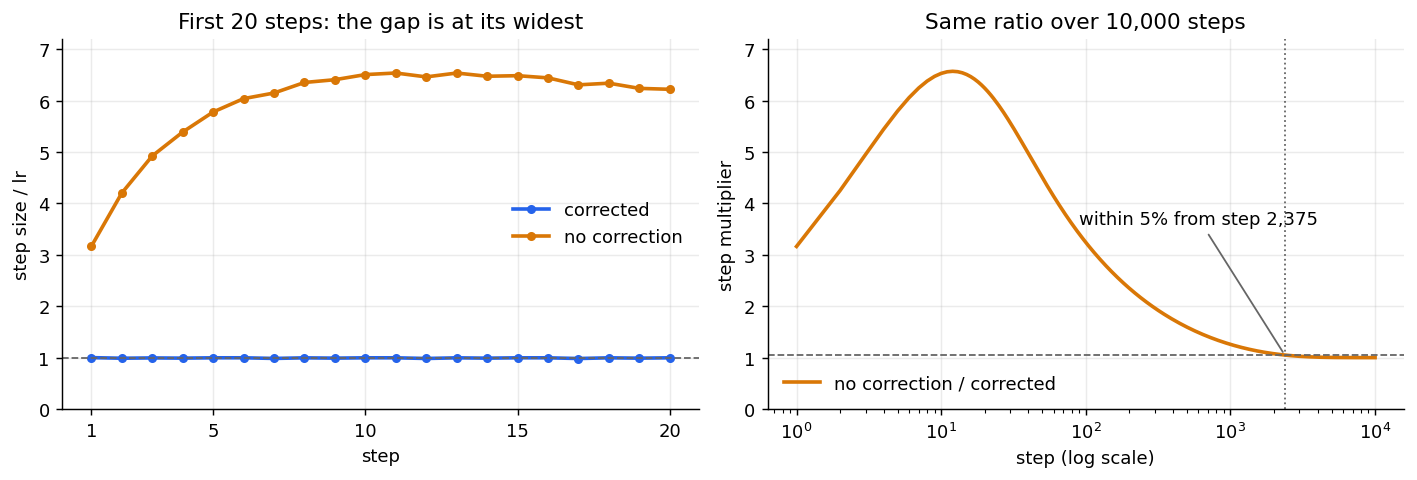

results/bias_real_model.png


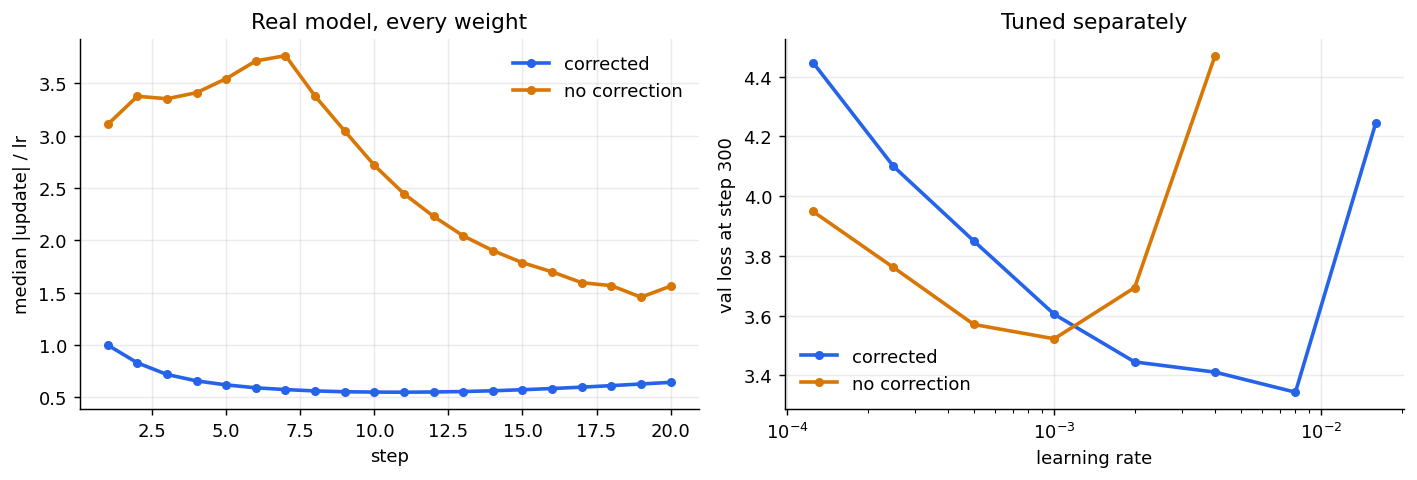

results/lr_vs_width.png


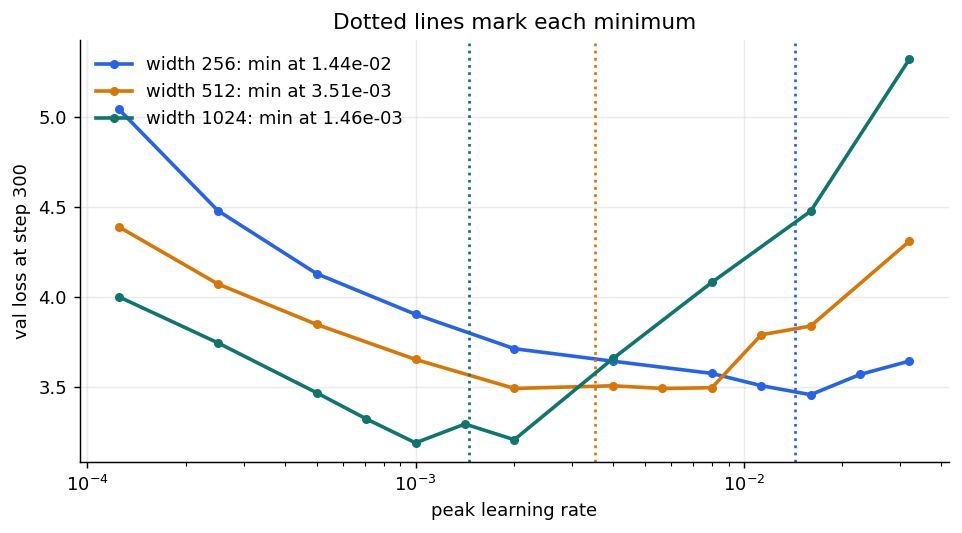

results/schedules.png


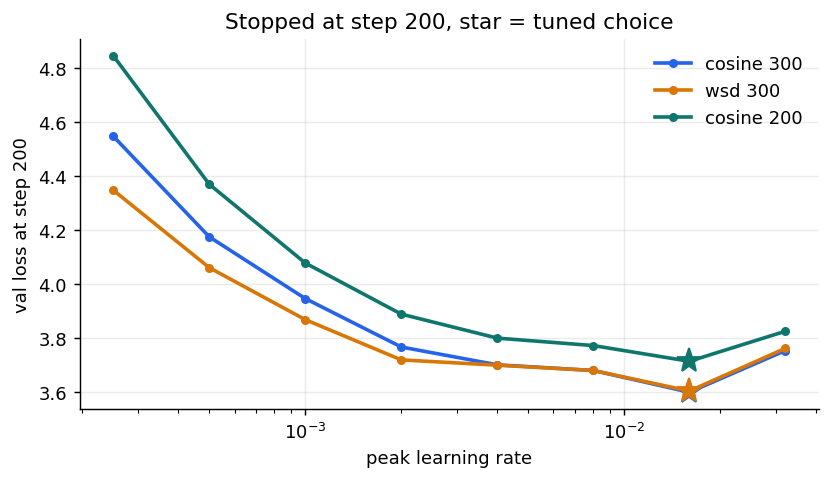

results/update_ratio.png


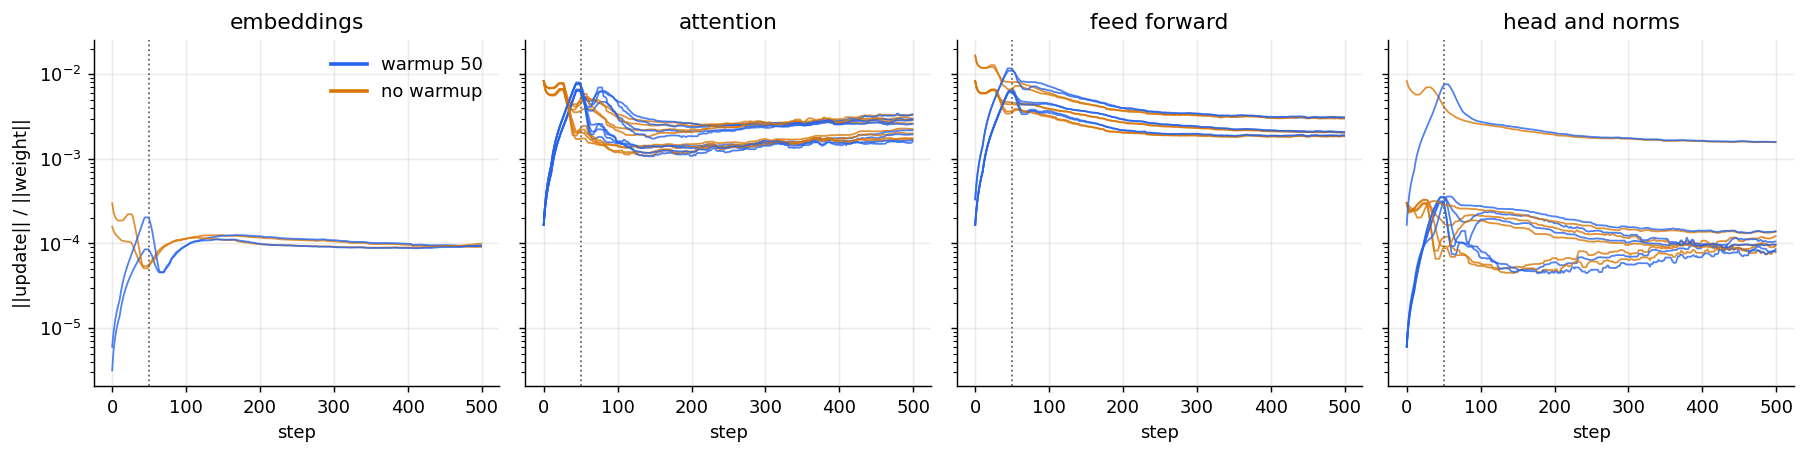

In [13]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob("results/*.png")):
    print(p); display(Image(p))
!cd /kaggle/working && zip -qr session-11-results.zip results log_gpu*.txt